# Analyzing Historical Stock/Revenue Data and Building a Dashboard

In [17]:
!pip install yfinance
!pip install plotly
!pip install beautifulsoup4
!pip install lxml
!pip install pandas
!pip install bs4
!pip install nbformat
!pip install --upgrade plotly
!pip install requests
!pip install html5lib 
!pip install numpy

In [18]:
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path

pd.set_option("display.max_rows", 10)
pd.set_option("display.width", 140)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

In [19]:
def get_stock_history(ticker: str, start: str = "2015-01-01") -> pd.DataFrame:
    """Return daily close price as 'Stock Price'."""
    hist = yf.Ticker(ticker).history(start=start, auto_adjust=False)
    if hist.empty:
        raise RuntimeError(f"No stock data returned for {ticker}.")
    out = hist.reset_index()[["Date", "Close"]].rename(columns={"Close":"Stock Price"})
    out["Date"] = pd.to_datetime(out["Date"]).dt.date
    return out

def _extract_total_revenue_from_quarterly(df: pd.DataFrame) -> pd.Series:
    """Locate a revenue-like row across yfinance versions; fallback to first row."""
    if df is None or df.empty:
        raise ValueError("Quarterly statement is empty.")
    candidates = [
        "Total Revenue", "TotalRevenue", "Total revenue",
        "Revenue", "Total Revenues", "TotalRevenueNet", "Total Net Revenue"
    ]
    for label in candidates:
        if label in df.index:
            return df.loc[label]
    return df.iloc[0]

def get_quarterly_revenue(ticker: str, company_name: str) -> pd.DataFrame:
    """Quarterly revenue (Billions USD) from yfinance income statements."""
    t = yf.Ticker(ticker)
    q = None
    for attr in ("quarterly_income_stmt", "quarterly_financials"):
        try:
            q = getattr(t, attr)
        except Exception:
            q = None
        if isinstance(q, pd.DataFrame) and not q.empty:
            break
    if q is None or q.empty:
        raise RuntimeError(f"Could not retrieve quarterly statements for {ticker}")
    rev_series = _extract_total_revenue_from_quarterly(q)
    df = rev_series.T.reset_index()
    df.columns = ["Date", "Revenue"]
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce").dt.date
    df["Revenue (Billions USD)"] = pd.to_numeric(df["Revenue"], errors="coerce") / 1e9
    df["Company"] = company_name
    df = df.dropna(subset=["Date", "Revenue (Billions USD)"]).sort_values("Date")
    return df[["Date", "Revenue (Billions USD)", "Company"]]

def make_price_vs_revenue_dashboard(price_df: pd.DataFrame, rev_df: pd.DataFrame, title: str):
    """Dual-axis Plotly chart: bars=Revenue (left), line=Price (right)."""
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(
        go.Bar(x=rev_df["Date"], y=rev_df["Revenue (Billions USD)"], name="Revenue (B USD)", opacity=0.6),
        secondary_y=False,
    )
    fig.add_trace(
        go.Scatter(x=price_df["Date"], y=price_df["Stock Price"], name="Stock Price", mode="lines"),
        secondary_y=True,
    )
    fig.update_layout(
        title=title,
        xaxis_title="Date",
        yaxis_title="Revenue (Billions USD)",
        legend_title="Series",
        bargap=0.15,
        hovermode="x unified",
        template="plotly_white",
        height=600,
    )
    fig.update_yaxes(title_text="Stock Price (USD)", secondary_y=True)
    return fig

### Question 1 - Extracting Tesla Stock Data Using yfinance

In [20]:
tsla_price = get_stock_history("TSLA", start="2015-01-01")
display(tsla_price.head())
tsla_price.to_csv(DATA_DIR / "tesla_stock.csv", index=False)
print("Saved:", DATA_DIR / "tesla_stock.csv")

,Date,Stock Price
0,2015-01-02,14.620667
1,2015-01-05,14.006000
2,2015-01-06,14.085333
3,2015-01-07,14.063333
4,2015-01-08,14.041333


Saved: data/tesla_stock.csv


### Question 2 - Extracting Tesla Revenue Data Using Webscraping

In [21]:
tsla_rev = get_quarterly_revenue("TSLA", "Tesla")
display(tsla_rev.tail())
tsla_rev.to_csv(DATA_DIR / "tesla_revenue.csv", index=False)
print("Saved:", DATA_DIR / "tesla_revenue.csv")

,Date,Revenue (Billions USD),Company
4,2024-06-30,25.500,Tesla
3,2024-09-30,25.182,Tesla
2,2024-12-31,25.707,Tesla
1,2025-03-31,19.335,Tesla
0,2025-06-30,22.496,Tesla


Saved: data/tesla_revenue.csv


### Question 3 - Extracting GameStop Stock Data Using yfinance

In [22]:
gme_price = get_stock_history("GME", start="2015-01-01")
display(gme_price.head())
gme_price.to_csv(DATA_DIR / "gamestop_stock.csv", index=False)
print("Saved:", DATA_DIR / "gamestop_stock.csv")

,Date,Stock Price
0,2015-01-02,8.4500
1,2015-01-05,8.6800
2,2015-01-06,8.4225
3,2015-01-07,8.3250
4,2015-01-08,8.4225


Saved: data/gamestop_stock.csv


### Question 4 - Extracting GameStop Revenue Data Using Webscraping

In [23]:
gme_rev = get_quarterly_revenue("GME", "GameStop")
display(gme_rev.tail())
gme_rev.to_csv(DATA_DIR / "gamestop_revenue.csv", index=False)
print("Saved:", DATA_DIR / "gamestop_revenue.csv")

,Date,Revenue (Billions USD),Company
4,2024-07-31,0.7983,GameStop
3,2024-10-31,0.8603,GameStop
2,2025-01-31,1.2826,GameStop
1,2025-04-30,0.7324,GameStop
0,2025-07-31,0.9722,GameStop


Saved: data/gamestop_revenue.csv


### Question 5 - Tesla Stock and Revenue Dashboard

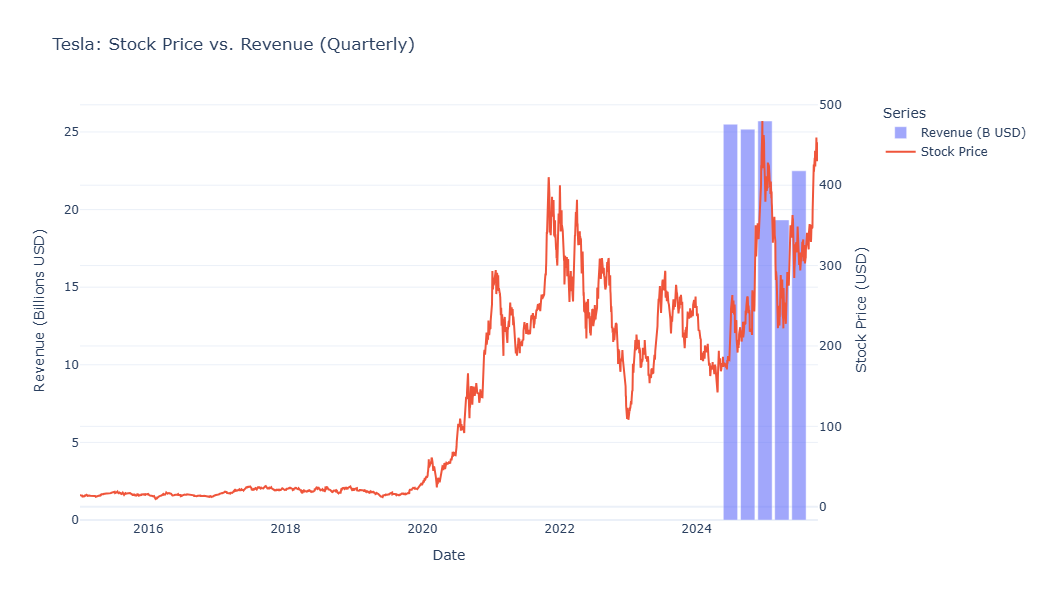

Saved: tesla_dashboard.html


In [24]:
fig_tsla = make_price_vs_revenue_dashboard(tsla_price, tsla_rev, "Tesla: Stock Price vs. Revenue (Quarterly)")
fig_tsla.show()
fig_tsla.write_html("tesla_dashboard.html")
print("Saved: tesla_dashboard.html")

### Question 6 - GameStop Stock and Revenue Dashboard

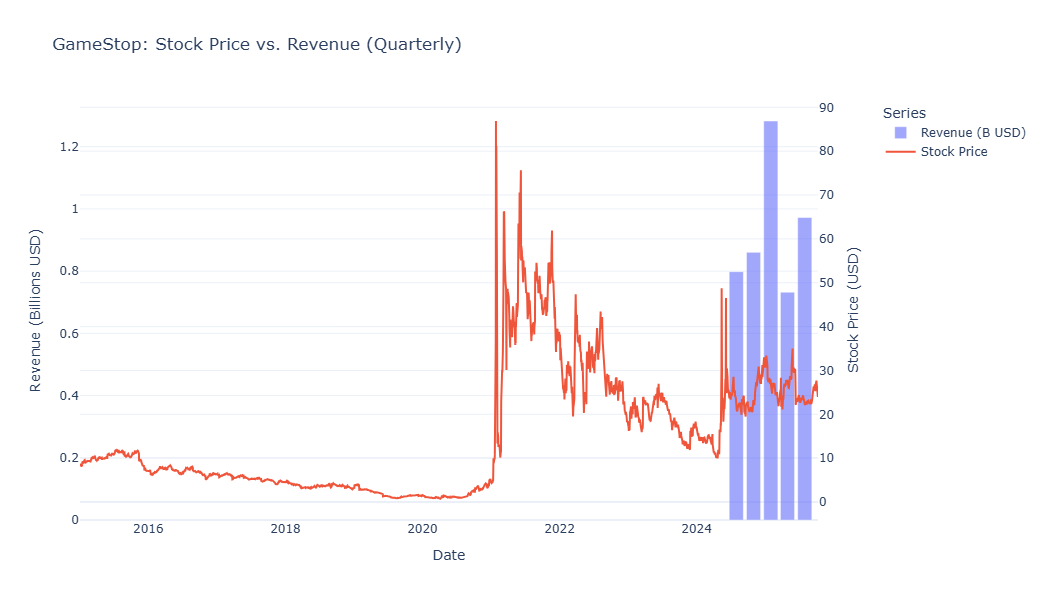

Saved: gamestop_dashboard.html


In [25]:
fig_gme = make_price_vs_revenue_dashboard(gme_price, gme_rev, "GameStop: Stock Price vs. Revenue (Quarterly)")
fig_gme.show()
fig_gme.write_html("gamestop_dashboard.html")
print("Saved: gamestop_dashboard.html")

###### NUOYU HAN